# 02. Пошук ознак і базова модель XGBoost

**Етап 02 з 13** · NASA C-MAPSS FD001 · RUL prediction


In [7]:
import os
import time
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
# import optuna
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from xgboost import XGBRegressor

DATA_DIR = Path(os.environ.get("FD001_DIR", "/content/drive/MyDrive/predictive_maintenance"))
SEED = 42
VALIDATION_SIZE = 0.2
N_SPLITS = 5
N_TRIALS = int(os.environ.get("N_TRIALS", 100))
TARGET = "RUL"
ID_COL = "unit_id"
TOP_SENSORS = ["sensor_11", "sensor_4", "sensor_12", "sensor_7", "sensor_15"]
XGB_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає, XGBoost на CPU")

GPU: немає, XGBoost на CPU


### MLflow

In [ ]:
import mlflow

# Ваша адреса ngrok
NGROK_URL = "https://stage-broom-alkalize.ngrok-free.dev"

# Додаємо заголовок для пропуску сторінки ngrok
os.environ["MLFLOW_TRACKING_SERVER_CERT_VERIFY"] = "false"
os.environ["HTTP_HEADER_NGROK_SKIP_BROWSER_WARNING"] = "true"

mlflow.set_tracking_uri(NGROK_URL)
mlflow.set_experiment("predictive_maintenance_colab")

## 1. Дані

In [10]:
COLUMNS = (
    ["unit_id", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)


def load_train(data_dir):
    """Читає train_FD001.txt і рахує RUL як кількість циклів до останнього циклу двигуна."""
    train = pd.read_csv(data_dir / "train_FD001.txt", sep=r"\s+", header=None, names=COLUMNS)
    train[TARGET] = train.groupby(ID_COL)["cycle"].transform("max") - train["cycle"]
    return train

train = load_train(DATA_DIR)
print("Train:", train.shape, "двигунів:", train[ID_COL].nunique())

Train: (20631, 27) двигунів: 100


In [11]:
splitter = GroupShuffleSplit(n_splits=1, test_size=VALIDATION_SIZE, random_state=SEED)
train_idx, val_idx = next(splitter.split(X=train, groups=train[ID_COL]))

train_df = train.iloc[train_idx].copy()
val_df = train.iloc[val_idx].copy()

assert set(train_df[ID_COL]).isdisjoint(set(val_df[ID_COL]))
assert len(train_df) + len(val_df) == len(train)

print(f"Train: {len(train_df)} рядків, {train_df[ID_COL].nunique()} двигунів")
print(f"Validation: {len(val_df)} рядків, {val_df[ID_COL].nunique()} двигунів")

Train: 16561 рядків, 80 двигунів
Validation: 4070 рядків, 20 двигунів


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Ознаки

In [12]:
# Базові набори ознак (без unit_id і RUL)
features_all = [c for c in train_df.columns if c not in [ID_COL, TARGET]]
features_no_cycle = [c for c in features_all if c != "cycle"]
constant_features = [c for c in features_all if train_df[c].nunique() <= 1]
features_no_constant = [c for c in features_all if c not in constant_features]
SENSOR_FEATURES = [c for c in features_no_constant if c.startswith("sensor_")]

print("Усі ознаки:", len(features_all))
print("Без cycle:", len(features_no_cycle))
print("Константні:", constant_features)
print("Без констант:", len(features_no_constant))

Усі ознаки: 25
Без cycle: 24
Константні: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Без констант: 18


### 2.1 Ковзні статистики і дельти

Одна функція `add_engine_features` рахує ковзні статистики (mean, std, min, max, range) і дельти за лагом.
Групи для відбору описано в `FEATURE_GROUPS`.

In [13]:
# min_periods ковзного вікна: std потребує щонайменше 2 значення (як в оригіналі)
MIN_PERIODS = {"mean": 1, "std": 2, "min": 1, "max": 1, "range": 1}


def _rolling_stat(series, stat, window):
    """Ковзна статистика ряду; для range повертає max - min у вікні."""
    roll = series.rolling(window=window, min_periods=MIN_PERIODS[stat])
    if stat == "range":
        return roll.max() - roll.min()
    return getattr(roll, stat)()


def column_name(sensor, stat, window):
    """Назва ознаки: sensor_11_delta_5 для дельти, sensor_11_rolling_std_5 для ковзної статистики."""
    if stat == "delta":
        return f"{sensor}_delta_{window}"
    return f"{sensor}_rolling_{stat}_{window}"


def add_engine_features(df, sensors, stat, windows):
    """Додає ознаку stat (mean, std, min, max, range або delta) для кожного сенсора і вікна по кожному двигуну."""
    df = df.sort_values([ID_COL, "cycle"]).copy()
    for sensor in sensors:
        grouped = df.groupby(ID_COL)[sensor]
        for window in windows:
            name = column_name(sensor, stat, window)
            if stat == "delta":
                df[name] = grouped.diff(window)
            else:
                df[name] = grouped.transform(lambda s, w=window: _rolling_stat(s, stat, w))
    return df

In [14]:
# Групи для відбору: назва -> (статистики, вікно або лаг). Усі по TOP_SENSORS.
FEATURE_GROUPS = {
    "delta_5": (["delta"], 5),
    "delta_10": (["delta"], 10),
    "rolling_std_5": (["std"], 5),
    "rolling_std_10": (["std"], 10),
    "rolling_min_max_5": (["min", "max"], 5),
    "rolling_min_max_10": (["min", "max"], 10),
    "rolling_range_5": (["range"], 5),
    "rolling_range_10": (["range"], 10),
}
MEAN_WINDOWS = (5, 10)


def add_group_features(df):
    """Додає до df колонки всіх груп FEATURE_GROUPS по TOP_SENSORS."""
    for stats, window in FEATURE_GROUPS.values():
        for stat in stats:
            df = add_engine_features(df, TOP_SENSORS, stat, [window])
    return df


def build_feature_frame(df):
    """Повна таблиця ознак: ковзні середні по всіх сенсорах і групи по TOP_SENSORS.

    Повертає рядки у тому самому порядку, що і вхідний df.
    """
    df = add_engine_features(df, SENSOR_FEATURES, "mean", MEAN_WINDOWS)
    return add_group_features(df).loc[df.index]


def mean_columns(sensors):
    """Колонки ковзних середніх для сенсорів (спочатку сенсор, потім вікно)."""
    return [f"{s}_rolling_mean_{w}" for s in sensors for w in MEAN_WINDOWS]


def group_columns(group):
    """Колонки групи з FEATURE_GROUPS по TOP_SENSORS (спочатку сенсор, потім статистика)."""
    stats, window = FEATURE_GROUPS[group]
    return [column_name(s, st, window) for s in TOP_SENSORS for st in stats]


# Усі іменовані групи ознак для експериментів: назва -> колонки
GROUP_COLUMNS = {
    "rolling_mean_top5": mean_columns(TOP_SENSORS),
    "rolling_mean_all": mean_columns(SENSOR_FEATURES),
    **{g: group_columns(g) for g in FEATURE_GROUPS},
}


def cols_of(groups):
    """Список колонок для набору груп."""
    return [col for g in groups for col in GROUP_COLUMNS[g]]


train_feat = build_feature_frame(train_df)
val_feat = build_feature_frame(val_df)

missing = [c for cols in GROUP_COLUMNS.values() for c in cols
           if c not in train_feat.columns or c not in val_feat.columns]
assert not missing, missing
assert train_feat.index.equals(train_df.index)

print("Ознак у групах:", {g: len(c) for g, c in GROUP_COLUMNS.items()})
print("NaN у ковзних середніх:", train_feat[mean_columns(SENSOR_FEATURES)].isna().sum().sum())

Ознак у групах: {'rolling_mean_top5': 10, 'rolling_mean_all': 30, 'delta_5': 5, 'delta_10': 5, 'rolling_std_5': 5, 'rolling_std_10': 5, 'rolling_min_max_5': 10, 'rolling_min_max_10': 10, 'rolling_range_5': 5, 'rolling_range_10': 5}
NaN у ковзних середніх: 0


### 2.2 Кореляції з RUL і відбір за ними

,RUL
cycle,-0.722
sensor_11,-0.684
sensor_4,-0.666
sensor_12,0.658
sensor_7,0.645
sensor_15,-0.631
sensor_21,0.624
sensor_20,0.619
sensor_2,-0.597
sensor_17,-0.596


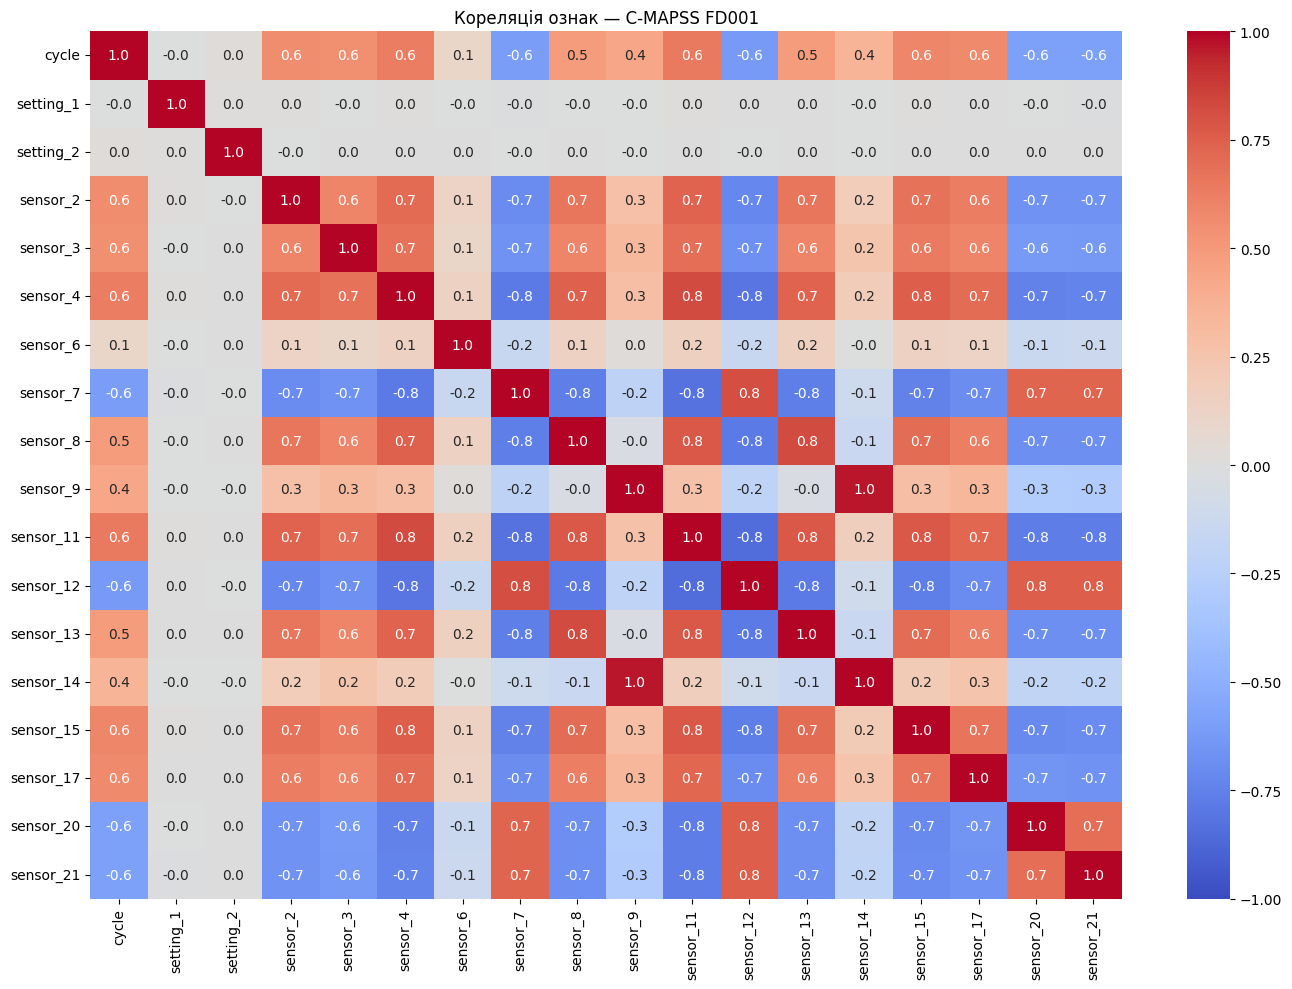

A — All non-constant: 18 ознак
B — Top 8 correlation: 8 ознак
C — Correlation >= 0.3: 15 ознак


In [15]:
correlations = (
    train_df[features_all + [TARGET]].corr(method="pearson")[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)
display(correlations.round(3))

plt.figure(figsize=(14, 10))
sns.heatmap(train_df[features_no_constant].corr(), cmap="coolwarm", center=0,
            vmin=-1, vmax=1, annot=True, fmt=".1f")
plt.title("Кореляція ознак — C-MAPSS FD001")
plt.tight_layout()
plt.show()

abs_corr = correlations.abs().sort_values(ascending=False)
CORR_SETS = {
    "A — All non-constant": features_no_constant,
    "B — Top 8 correlation": abs_corr.head(8).index.tolist(),
    "C — Correlation >= 0.3": abs_corr[abs_corr >= 0.3].index.tolist(),
}
for name, feats in CORR_SETS.items():
    print(f"{name}: {len(feats)} ознак")

## MLflow

In [27]:
def log_baseline_run(config_name, model, pred_type, features, metrics):
  """
  Автоматично логує один зауск експерименту в MLflow.
  """

  run_name = f"{config_name} | {pred_type}"

  with mlflow.start_run(run_name=run_name):
    mlflow.log_params({
        "experiment_name": config_name,
        "model_type": model.__class__.__name__,
        "prediction_type": pred_type,
        "num_features": len(features),
        "features_list": ", ".join(features),
    })

    mlflow.log_metrics(metrics)

## 3. Експерименти

Усі експерименти — HistGradientBoostingRegressor (`max_iter=100`, `learning_rate=0.1`, `max_leaf_nodes=15`, `l2_regularization=1.0`, seed 42) на train, метрики на validation.

In [28]:
def make_hgbr():
    """HistGradientBoostingRegressor з фіксованими параметрами і seed SEED."""
    return HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=SEED,
    )


def evaluate(y_true, y_pred):
    """MAE, RMSE і R2 для одного набору прогнозів."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


def fit_predict(model, train_frame, val_frame, features, clip):
    """Навчає модель на train_frame і повертає прогнози на val_frame; clip=True відсікає значення нижче нуля."""
    model.fit(train_frame[features], train_frame[TARGET])
    pred = model.predict(val_frame[features])
    return np.clip(pred, 0, None) if clip else pred


def run_experiments(configs, clip):
    """Запускає HGBR для кожної конфігурації (назва, ознаки, мета-дані); повертає одну таблицю метрик на validation."""
    rows = []
    for name, features, meta in configs:
        model = make_hgbr()
        pred = fit_predict(model, train_feat, val_feat, features, clip)

        metrics = evaluate(val_feat[TARGET], pred)

        rows.append({"Experiment": name, **meta, "Features": len(features),
                     **metrics})

        pred_type = "Clipped at 0" if clip else " Raw"
        run_name = f"{name} | {pred_type}"

        with mlflow.start_run(run_name=run_name):
          mlflow.log_params({
              "experiment_name": name,
              "model_type": model.__class__.__name__,
              "prediction_type": pred_type,
              "num_features": len(features),
              **meta
          })
          mlflow.log_metrics(metrics)

    return pd.DataFrame(rows)

### 3.1 Базові моделі (LinearRegression і HGBR)

In [29]:
BASELINE_MODELS = {
    "A — All features": (LinearRegression, features_all),
    "B — Without cycle": (LinearRegression, features_no_cycle),
    "C — Without constants": (LinearRegression, features_no_constant),
    "D - HGBR": (make_hgbr, features_all),
}

In [30]:
baseline_rows = []
baseline_preds = {}

for name, (factory, features) in BASELINE_MODELS.items():

    model = factory()
    raw = fit_predict(model, train_feat, val_feat, features, clip=False)
    baseline_preds[name] = raw

    for version, pred in [("Raw", raw), ("Clipped at 0", np.clip(raw, 0, None))]:

        metrics = evaluate(val_feat[TARGET], pred)

        baseline_rows.append({"Model": name, "Prediction": version, "Features": len(features),
                              **metrics})

        log_baseline_run(
            config_name = name,
            model= model,
            pred_type= version,
            features= features,
            metrics=metrics
        )

baseline_df = pd.DataFrame(baseline_rows).sort_values(["Prediction", "MAE"]).round(3)
display(baseline_df)

🏃 View run A — All features | Raw at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/4a700cac5b8a4b1fbe995aed04cd9c01
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run A — All features | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/a8445b313d6e45d6931ac508d7da9b46
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run B — Without cycle | Raw at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/3afc5157ed984bd0a6af594b1e29baa7
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run B — Without cycle | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/99b666e91a2a4c6a8a60dfb0c49688bb
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run C — Without constants | Raw at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/

,Model,Prediction,Features,MAE,RMSE,R2
7,D - HGBR,Clipped at 0,25,23.153,30.296,0.787
5,C — Without constants,Clipped at 0,18,24.504,31.272,0.773
1,A — All features,Clipped at 0,25,24.504,31.272,0.773
3,B — Without cycle,Clipped at 0,24,29.143,37.548,0.673
6,D - HGBR,Raw,25,23.153,30.296,0.787
4,C — Without constants,Raw,18,25.155,31.656,0.768
0,A — All features,Raw,25,25.155,31.656,0.768
2,B — Without cycle,Raw,24,30.111,38.133,0.663


### 3.2 Набори ознак за кореляцією (clip=True)

In [31]:
corr_df = run_experiments(
    [(name, feats, {}) for name, feats in CORR_SETS.items()],
    clip=True,
).sort_values("MAE").reset_index(drop=True)
display(corr_df.round(3))

🏃 View run A — All non-constant | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/adb1830b5db94773b918c85672893b11
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run B — Top 8 correlation | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/1f6847c8ac794c6a987603b6b2b70cfa
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run C — Correlation >= 0.3 | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/6085f042b84f4e12995a13db5e060124
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1


,Experiment,Features,MAE,RMSE,R2
0,A — All non-constant,18,23.153,30.296,0.787
1,C — Correlation >= 0.3,15,23.181,30.332,0.787
2,B — Top 8 correlation,8,23.402,30.112,0.790


### 3.3 Одна група або пара груп ознак (clip=True)

Ковзне середнє, дельти, std, min-max і range. Baseline один раз; кожна серія додає свої групи до 18 базових ознак.

In [ ]:
SINGLE_SERIES = {
    "Ковзне середнє": [
        ("Rolling Top 5", ["rolling_mean_top5"]),
        ("Rolling all sensors", ["rolling_mean_all"]),
    ],
    "Дельти": [
        ("Delta_5", ["delta_5"]),
        ("Delta_10", ["delta_10"]),
        ("Delta_5 + Delta_10", ["delta_5", "delta_10"]),
    ],
    "Rolling std": [
        ("Rolling_std_5", ["rolling_std_5"]),
        ("Rolling_std_10", ["rolling_std_10"]),
        ("Rolling_std_5 + 10", ["rolling_std_5", "rolling_std_10"]),
    ],
    "Rolling min-max": [
        ("Rolling_min_max_5", ["rolling_min_max_5"]),
        ("Rolling_min_max_10", ["rolling_min_max_10"]),
        ("Rolling_min_max_5 + 10", ["rolling_min_max_5", "rolling_min_max_10"]),
    ],
    "Rolling range": [
        ("Rolling_range_5", ["rolling_range_5"]),
        ("Rolling_range_10", ["rolling_range_10"]),
        ("Rolling_range_5 + 10", ["rolling_range_5", "rolling_range_10"]),
    ],
}

single_configs = [("Baseline", features_no_constant, {"Серія": "—"})]
single_configs += [
    (name, features_no_constant + cols_of(groups), {"Серія": series})
    for series, items in SINGLE_SERIES.items()
    for name, groups in items
]
single_df = run_experiments(single_configs, clip=True).sort_values("MAE").reset_index(drop=True)

🏃 View run Baseline | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/f9503d636464443584a0b2c261df1c4f
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run Rolling Top 5 | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/dc235c4d148d4f2eb5497f0b427731e9
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run Rolling all sensors | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/64af4745298649978fa3d0827dcaa755
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run Delta_5 | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/596d6e1ff4134dc682390de29b298538
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run Delta_10 | Clipped at 0 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/267d0

### 3.4 Перебір комбінацій груп (2^8 = 256, clip=False)

Перебираємо всі підмножини з 8 груп `FEATURE_GROUPS` поверх 18 базових ознак.

In [ ]:
group_names = list(FEATURE_GROUPS)
search_configs = []

for k in range(len(group_names) + 1):
    for selected in combinations(group_names, k):
        name = " + ".join(selected) if selected else "Baseline"
        search_configs.append((name, features_no_constant + cols_of(selected), {"n_groups": k}))

#вибір груп іде за метриками на validation, а потім ті самі метрики використовуються для оцінки (3.6, 4.2). 
# Оптимістична оцінка. Не змінено.
search_df = (
    run_experiments(search_configs, clip=False)
    .sort_values(["MAE", "RMSE"])
    .reset_index(drop=True)
)

### 3.5 Cross-validation (GroupKFold, 5 фолдів по двигунах на train)

Кандидати взято з результатів 3.4. Оцінка на train без validation.

In [ ]:
CV_CANDIDATES = {
    "Baseline": [],
    "Candidate_1": ["delta_5", "delta_10", "rolling_min_max_5", "rolling_range_5"],
    "Candidate_2": ["delta_10", "rolling_std_5", "rolling_min_max_5", "rolling_range_5"],
    "Candidate_3": ["delta_5", "delta_10", "rolling_std_5", "rolling_min_max_5", "rolling_range_5"],
}


def run_group_cv(data, candidates, n_splits=N_SPLITS):
    """GroupKFold по двигунах: рахує крос-валідацію та логує середні метрики кандидатів в MLflow."""
    rows = []
    cv = GroupKFold(n_splits=n_splits)

    # Проходимо по кожному кандидату
    for cand, groups in candidates.items():
        features = features_no_constant + cols_of(groups)
        cand_fold_rows = []

        # Проходимо по фолдах
        for fold, (tr_idx, va_idx) in enumerate(cv.split(data, groups=data[ID_COL]), start=1):
            tr, va = data.iloc[tr_idx], data.iloc[va_idx]
            pred = fit_predict(make_hgbr(), tr, va, features, clip=False)

            metrics = evaluate(va[TARGET], pred)

            fold_data = {
                "candidate": cand,
                "fold": fold,
                "n_train_engines": tr[ID_COL].nunique(),
                "n_val_engines": va[ID_COL].nunique(),
                "n_features": len(features),
                **metrics,
            }
            cand_fold_rows.append(fold_data)
            rows.append(fold_data)

        # Обчислюємо середні метрики по фолдах для цього кандидата
        cand_df = pd.DataFrame(cand_fold_rows)
        mae_mean, mae_std = cand_df["MAE"].mean(), cand_df["MAE"].std()
        rmse_mean, rmse_std = cand_df["RMSE"].mean(), cand_df["RMSE"].std()
        r2_mean, r2_std = cand_df["R2"].mean(), cand_df["R2"].std()

        # Відправляємо кандидатний Run в MLflow
        run_name = f"CV | {cand}"
        with mlflow.start_run(run_name=run_name):
            # Параметри кандидата
            mlflow.log_params({
                "candidate_name": cand,
                "model_type": "HistGradientBoostingRegressor",
                "n_splits": n_splits,
                "num_features": len(features),
                "groups_used": ", ".join(groups) if groups else "None",
            })

            # Агреговані метрики крос-валідації
            mlflow.log_metrics({
                "MAE_mean": mae_mean,
                "MAE_std": mae_std,
                "RMSE_mean": rmse_mean,
                "RMSE_std": rmse_std,
                "R2_mean": r2_mean,
                "R2_std": r2_std,
            })

    return pd.DataFrame(rows)


cv_results = run_group_cv(train_feat, CV_CANDIDATES)
cv_summary = (
    cv_results.groupby("candidate")
    .agg(
        MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"), R2_std=("R2", "std"),
    )
    .sort_values("MAE_mean")
)

🏃 View run CV | Baseline at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/463fa098e7464d85b8eaf1b8bfbcab77
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run CV | Candidate_1 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/900ca8ac8cb24100910ca73aa8d932b0
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run CV | Candidate_2 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/2dde1fb8f85e42c8a409901b7e1e6841
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run CV | Candidate_3 at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/4779b642edc1406a9bf8056e6cb14ce2
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1


### 3.6 XGBoost на validation (clip=False)

Порівнюємо baseline з набором `BEST_GROUPS` (той самий, що Candidate_1 у 3.5 і найкращий у переборі 3.4).

In [42]:
def log_xgb_run(config_name, model, features, metrics, extra_params=None):
  """
  Логує запуск XGBoost в MLflow із гіперпараметром та часу навчання.
  """
  run_name = f"XGBoost | {config_name}"

  with mlflow.start_run(run_name = run_name):
      params = {
          "config_name": config_name,
          "model_types": model.__class__.__name__,
          "num_features": len(features),
      }

      if extra_params:
          params.update(extra_params)

      mlflow.log_params(params)
      mlflow.log_metrics(metrics)

In [40]:
BEST_GROUPS = ["delta_5", "delta_10", "rolling_min_max_5", "rolling_range_5"]

XGB_PARAMS = dict(
    objective="reg:squarederror",
    eval_metric="mae",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    tree_method="hist",
    device=XGB_DEVICE,
    random_state=SEED,
    n_jobs=-1,
)

xgb_configs = {
    "Baseline": features_no_constant,
    "Best_4groups": features_no_constant + cols_of(BEST_GROUPS),
}

In [43]:
xgb_rows = []
for name, features in xgb_configs.items():
    model = XGBRegressor(**XGB_PARAMS)

    start = time.perf_counter()
    model.fit(train_feat[features], train_feat[TARGET])
    elapsed = time.perf_counter() - start

    pred = model.predict(val_feat[features])
    metrics = {
        **evaluate(val_feat[TARGET], pred),
        "train_time_sec": elapsed
    }

    xgb_rows.append({
        "model": name,
        "n_features": len(features),
        **metrics
    })

    log_xgb_run(
        config_name=name,
        model=model,
        features=features,
        metrics=metrics,
        extra_params=XGB_PARAMS
    )

xgb_df = pd.DataFrame(xgb_rows).sort_values("MAE").reset_index(drop=True)
# display(xgb_df.round(3))

🏃 View run XGBoost | Baseline at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/e9179adb28014891a2682b97fceafc5b
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
🏃 View run XGBoost | Best_4groups at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/415d77c8a7884eda9778a5056f12f428
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1


### 3.7 Optuna: підбір гіперпараметрів XGBoost (CV по train)

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv = GroupKFold(n_splits=N_SPLITS)


def optimize_xgboost(data, features, study_name, n_trials=N_TRIALS):
    """Підбирає гіперпараметри XGBoost (TPE, seed SEED) за середнім MAE по фолдах GroupKFold на data."""
    X, y = data[features], data[TARGET]
    folds = list(cv.split(X, y, groups=data[ID_COL]))

    def objective(trial):
        params = {
            "objective": "reg:squarederror",
            "eval_metric": "mae",
            "tree_method": "hist",
            "device": XGB_DEVICE,
            "n_jobs": -1,
            "random_state": SEED,
            "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "min_child_weight": trial.suggest_float("min_child_weight", 0.5, 20.0, log=True),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100.0, log=True),
            "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        }
        fold_maes = []
        for tr_idx, va_idx in folds:
            model = XGBRegressor(**params)
            model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
            fold_maes.append(mean_absolute_error(y.iloc[va_idx], model.predict(X.iloc[va_idx])))
        return float(np.mean(fold_maes))

    study = optuna.create_study(
        study_name=study_name,
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
    )
    start = time.perf_counter()
    study.optimize(objective, n_trials=n_trials, n_jobs=1, show_progress_bar=True)
    elapsed = time.perf_counter() - start

    print(f"\nStudy: {study_name}; trials: {len(study.trials)}; час: {elapsed / 60:.2f} хв")
    print(f"Best CV MAE: {study.best_value:.4f}")
    print("Best parameters:", study.best_params)
    return study


OPTUNA_CASES = {
    "xgb_baseline": features_no_constant,
    "xgb_best_4groups": features_no_constant + cols_of(BEST_GROUPS),
}
studies = {
    name: optimize_xgboost(train_feat, feats, study_name=name, n_trials=N_TRIALS)
    for name, feats in OPTUNA_CASES.items()
}

## 4. Результати

### 4.1 Похибки HGBR (baseline D, validation)

In [ ]:
hgbr_raw = baseline_preds["D - HGBR"]
hgbr_clip = np.clip(hgbr_raw, 0, None)
y_val = val_feat[TARGET]

# TODO(review): діаграма розсіювання в оригіналі будувалась на відсіченому прогнозі, а таблиця похибок — на сирому. Залишено.
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_val, hgbr_clip, alpha=0.3)
lo, hi = min(y_val.min(), hgbr_clip.min()), max(y_val.max(), hgbr_clip.max())
ax.plot([lo, hi], [lo, hi], linestyle="--", color="r")
ax.set(xlabel="Actual RUL", ylabel="Predicted RUL", title="Actual vs Predicted RUL — HistGradientBoosting")
ax.grid(alpha=0.3)
plt.show()

error_df = val_feat[[ID_COL, "cycle", TARGET]].copy()
error_df["y_pred"] = hgbr_raw
error_df["error"] = error_df["y_pred"] - error_df[TARGET]
error_df["absolute_error"] = error_df["error"].abs()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(error_df["error"], bins=100, edgecolor="black")
ax.axvline(0, linestyle="--")
ax.set(xlabel="Prediction Error (Predicted - Actual)", ylabel="Number of observations",
       title="Prediction Error Distribution — HGBR")
ax.grid(alpha=0.2)
plt.show()

error_df["RUL_group"] = pd.cut(
    error_df[TARGET],
    bins=[-np.inf, 30, 90, np.inf],
    labels=["0–30", "31–90", ">90"],
)
group_metrics = (
    error_df.groupby("RUL_group", observed=False)
    .agg(samples=(TARGET, "size"), MAE=("absolute_error", "mean"), Mean_Error=("error", "mean"))
    .round(3)
)
display(group_metrics)

unit_errors = (
    error_df.groupby(ID_COL)
    .agg(MAE=("absolute_error", "mean"), Mean_Error=("error", "mean"), cycles=(TARGET, "size"))
    .sort_values("MAE", ascending=False)
)
display(unit_errors.head(10).round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, unit_id in zip(axes.flat, [84, 45, 91, 5]):
    unit = error_df[error_df[ID_COL] == unit_id].sort_values("cycle")
    ax.plot(unit["cycle"], unit[TARGET], label="Actual RUL")
    ax.plot(unit["cycle"], unit["y_pred"], label="Predicted RUL")
    ax.set(title=f"Engine {unit_id}", xlabel="Cycle", ylabel="RUL")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2 Зведена таблиця

Значення беруться з таблиць, отриманих вище.

In [ ]:
base = single_df.loc[single_df["Experiment"] == "Baseline"].iloc[0]
best_single = single_df.loc[single_df["Experiment"] != "Baseline"].iloc[0]
best_search = search_df.iloc[0]
xgb_by_name = xgb_df.set_index("model")

rows = [
    ("HGBR, validation", "Baseline", base["Features"], base["MAE"], base["RMSE"], base["R2"]),
    ("HGBR, validation", f"Найкраща одиночна: {best_single['Experiment']}",
     best_single["Features"], best_single["MAE"], best_single["RMSE"], best_single["R2"]),
    ("HGBR, validation", f"Найкраща комбінація: {best_search['Experiment']}",
     best_search["Features"], best_search["MAE"], best_search["RMSE"], best_search["R2"]),
    ("XGBoost, validation", "Baseline", xgb_by_name.loc["Baseline", "n_features"],
     xgb_by_name.loc["Baseline", "MAE"], xgb_by_name.loc["Baseline", "RMSE"], xgb_by_name.loc["Baseline", "R2"]),
    ("XGBoost, validation", "Best_4groups", xgb_by_name.loc["Best_4groups", "n_features"],
     xgb_by_name.loc["Best_4groups", "MAE"], xgb_by_name.loc["Best_4groups", "RMSE"], xgb_by_name.loc["Best_4groups", "R2"]),
]
for cand in ["Baseline", "Candidate_1"]:
    c = cv_summary.loc[cand]
    rows.append(("HGBR, CV 5 фолдів (середнє)", cand, np.nan, c["MAE_mean"], c["RMSE_mean"], c["R2_mean"]))
for name in OPTUNA_CASES:
    rows.append(("XGBoost, Optuna CV (train)", name, np.nan, studies[name].best_value, np.nan, np.nan))

summary = pd.DataFrame(rows, columns=["Етап", "Конфігурація", "Ознак", "MAE", "RMSE", "R2"])
display(summary.round(3))

## Висновки

- **Baseline** (HGBR, 18 ознак): MAE 23.153, RMSE 30.296, R2 0.787. Для HGBR відсікання від нуля не змінює результат; для LinearRegression — MAE 25.155 → 24.504. Лінійна модель слабша (24.504 проти 23.153).
- **Окремі групи** дають невеликий виграш: Delta_5 — MAE 22.979, Rolling_min_max_5 — 22.981, Delta_5 + Delta_10 — 22.983. Ковзне середнє по всіх сенсорах погіршує (24.375), по топ-5 — 23.375.
- **Перебір 256 комбінацій**: найкраща `delta_5 + delta_10 + rolling_min_max_5 + rolling_range_5` (43 ознаки) — MAE 22.752, RMSE 29.860, R2 0.793 (на 0.40 MAE, ~1.7%, краще за baseline). Топ-10 відрізняється на соті частки MAE, тож різниця між ними ймовірно шум.
- **5-фолдова CV по train не підтверджує виграш**: Baseline MAE 27.718 ± 2.569; Candidate_1 28.195 ± 2.826; Candidate_3 28.206; Candidate_2 28.219. Кандидати на validation кращі, але на CV гірші. Набори з групами не можна вважати покращенням без окремої перевірки.
- **XGBoost** (параметри за замовчуванням, validation): Baseline MAE 23.772, RMSE 31.452; Best_4groups MAE 23.284, RMSE 30.628. Набір вибрано на тому ж validation, тож оцінка оптимістична.
- **Optuna** (100 trials, CV по train): `xgb_baseline` — Best CV MAE 27.3085 (4.3 хв); `xgb_best_4groups` — 27.6924 (20.6 хв). Після підбору гіперпараметрів baseline кращий на 0.38. Групи ознак не дають виграшу на CV.
- **Похибки HGBR** (validation): за RUL 0–30 MAE 6.017 (n=620), 31–90 — 21.342 з систематичним завищенням (середня похибка +15.746), >90 — 28.841 (n=2250, середня похибка −3.283). Найгірші двигуни: 84 (MAE 46.8), 45 (42.1), 91 (42.1).


# Фінальне навчання та логування кращої моделі

In [44]:
# Фінальна конфігурація переможця
best_features = features_no_constant + cols_of(BEST_GROUPS)

final_model = XGBRegressor(**XGB_PARAMS)
final_model.fit(train_feat[best_features], train_feat[TARGET])

pred = final_model.predict(val_feat[best_features])
final_metrics = evaluate(val_feat[TARGET], pred)

# Логуємо фінальний "золотий" запуск
with mlflow.start_run(run_name="FINAL_BEST_XGBOOST") as run:
    mlflow.log_params(XGB_PARAMS)
    mlflow.log_metrics(final_metrics)

    # 🌟 Логуємо саму модель як артифакт
    mlflow.xgboost.log_model(final_model, artifact_path="model")

    # Зберігаємо ID запуску
    run_id = run.info.run_id

print(f"Фінальна модель залогована! Run ID: {run_id}")

2026/11/04 09:53:37 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run FINAL_BEST_XGBOOST at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1/runs/6b28ad199a6646079d9cc0ad48a37119
🧪 View experiment at: https://stage-broom-alkalize.ngrok-free.dev/#/experiments/1
Фінальна модель залогована! Run ID: 6b28ad199a6646079d9cc0ad48a37119


In [45]:
# Зберігаємо модель у JSON
final_model.save_model("best_xgboost_model.json")

# Скачуємо на ПК
from google.colab import files
files.download("best_xgboost_model.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>